# Table de modélisation : audit, métadonnées et redondances

Contributeurs : Cécile · Date : 31/10/2026

Table produite à la fin de feature_engineering (table_modelisation_bv.parquet) : une ligne par année × sous-bassin × type de bien, seulement les lignes où le prix et le prix N-1 sont renseignés. Trois objectifs :

- un fichier de métadonnées qui décrit chaque variable ;
- une seule variable par information (par exemple le taux plutôt que le nombre de faits) ;
- les corrélations entre variables, pour repérer les informations redondantes.

In [2]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

# config.py se trouve à la racine du projet : on remonte les dossiers jusqu'à le trouver
racine = Path.cwd()
while not (racine / "config.py").exists() and racine != racine.parent:
    racine = racine.parent
sys.path.insert(0, str(racine))
from config import DATA_RAW, DATA_OUT

pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)


## 1. Audit : contenu de la table

On charge la table et on regarde, pour chaque variable, son type, sa part de valeurs vides et son nombre de valeurs distinctes. Une variable qui n'a qu'une seule valeur, ou très peu, se repère tout de suite.

In [3]:
# Table lue par commun.py : index annee x sous_bassin_de_vie x type_bien
table = pd.read_parquet(DATA_OUT / "table_modelisation_bv.parquet")
print(table.shape)
print("Index :", table.index.names, "| unique :", table.index.is_unique)

# Lignes par année et par type de bien
display(table.groupby(level=["annee", "type_bien"]).size().unstack())

# Une ligne par variable : type, part de valeurs vides, nombre de valeurs distinctes
apercu = pd.DataFrame({
    "type": table.dtypes.astype(str),
    "% vides": table.isna().mean().mul(100).round(1),
    "valeurs distinctes": table.nunique(),
})
display(apercu)

(28450, 41)
Index : ['annee', 'sous_bassin_de_vie', 'type_bien'] | unique : True


type_bien,appartement,maison
annee,,
2015,691,1769
2016,717,1775
2017,746,1776
2018,774,1780
2019,805,1780
2020,857,1780
2021,878,1781
2022,912,1782
2023,861,1781


,type,% vides,valeurs distinctes
annee,int64,0.0,11
maison,int64,0.0,2
n_ventes,int64,0.0,1757
nb_ventes_n1,float64,0.0,1737
prix,float64,0.0,4683
part_indicateurs_estimes,float64,17.4,15336
taux3_vols_vehicules,float64,17.4,16283
taux3_vols_violents,float64,17.4,15655
taux3_vols_sans_violence,float64,17.4,16282
taux3_cambriolages,float64,17.4,16280


**Lecture**

- **28 450 lignes** (8 891 appartements, 19 559 maisons), années de prix 2015 à 2025, 41 colonnes. Index unique (année × sous-bassin × type de bien).
- **Une seule variable par information** : délinquance en taux lissés sur 3 ans, équipements en taux pour 10 000 habitants, densité de population, Filosofi contrôlé par la part des ménages couverts. Les nombres bruts et les trois variables redondantes (`part_suroccupes`, `part_parking`, `taux3_destructions`) ont été retirés dans le feature engineering.
- **Valeurs vides : seulement la délinquance, pour les prix 2015 et 2016** (17,4 % des lignes) : les faits commencent en 2016 et sont décalés d'un an. À partir de 2017, aucune valeur ne manque.
- **Photos fixes** : logement (2022), LOVAC (2023), Filosofi (2021), équipements (2025) et densité (2024) ont une valeur par sous-bassin, identique toutes les années (environ 1 810 valeurs distinctes). Les arrondissements de Paris, Lyon et Marseille ont chacun leur densité, calculée avec leur superficie réelle. Tourisme, transports et part des logements au taux complété ont moins de valeurs distinctes : beaucoup de sous-bassins y valent 0.
- **Ménages** : seule source du territoire qui varie d'une année à l'autre (recensements 2019 à 2022, 2023 = 2022, 2024 prolongé, 2025 = 2024). La taille moyenne des ménages, arrondie à 2 décimales, n'a que 115 valeurs distinctes.
- **Nombre restant** : `nb_ventes_n1` (ventes de N-1) suit la taille du sous-bassin ; son évolution entre N-2 et N-1 reste à décider. `n_ventes` (ventes de N) ne sert qu'au seuil de 20 ventes, jamais comme variable explicative.
- **`BV2022`** : bassin de vie de chaque sous-bassin, identifiant pour le test contre la naïve (bootstrap par bassin de vie), jamais une variable explicative.


## 2. Nature des variables : nombre ou taux, et base de calcul

Pour chaque variable : sa source, sa nature (nombre, taux, part, moyenne, prix) et sa base de calcul, relues dans le code du feature engineering. Un nombre suit d'abord la taille du sous-bassin ; un taux ou une part permet de comparer des territoires de tailles différentes.

In [4]:
# Pour chaque variable : (source, nature, base de calcul)
nature = {}

# DVF+ : année, type de bien, ventes, prix
nature["annee"]        = ("DVF+", "année", "année des prix (N)")
nature["maison"]       = ("DVF+", "indicatrice", "1 = maison, 0 = appartement")
nature["n_ventes"]     = ("DVF+", "nombre", "ventes de l'année N (sert seulement au seuil de 20 ventes)")
nature["nb_ventes_n1"] = ("DVF+", "nombre", "ventes de l'année N-1, additionnées au sous-bassin")
nature["prix"]         = ("DVF+", "prix (€/m²)", "médiane des prix au m² des ventes de N")
nature["prix_n1"]      = ("DVF+", "prix (€/m²)", "médiane des prix au m² des ventes de N-1")

# Délinquance (SSMSI) : faits et dénominateurs additionnés au sous-bassin, puis taux lissé sur 3 ans
# (destructions retirées dans le feature engineering : redondantes avec les vols sans violence)
FAMILLES = ["vols_vehicules", "vols_violents", "vols_sans_violence", "cambriolages",
            "stupefiants", "violences_intrafamiliales", "violences_sexuelles"]
for f in FAMILLES:
    denom = "1 000 logements" if f == "cambriolages" else "1 000 habitants"
    nature["taux3_" + f] = ("Délinquance", "taux",
        f"faits de N-3 à N-1 pour {denom} des mêmes années (1 an pour les prix 2017, 2 ans pour 2018)")
nature["part_indicateurs_estimes"] = ("Délinquance", "part (%)",
    "indicateurs estimés (secret statistique) sur 15, moyenne pondérée par la population")

# LOVAC (photo 2023)
nature["taux_vacance_complete"] = ("LOVAC", "taux (%)",
    "taux communal (complété par l'EPCI si masqué), moyenne pondérée par les logements du recensement (P22_LOG)")
nature["part_logements_taux_impute"] = ("LOVAC", "part (%)",
    "logements situés dans une commune dont le taux a été complété par l'EPCI / P22_LOG")

# Équipements (BPE 2025, photo) : équipements et habitants 2024 additionnés au sous-bassin
for d in ["commerces", "sante", "services", "sports", "tourisme", "transports"]:
    nature["taux_equip_" + d] = ("Équipements", "taux", "équipements du domaine pour 10 000 habitants (2024)")

# Densité (photo) : habitants 2024 et superficie additionnés au sous-bassin
nature["densite_population"] = ("Densité", "taux",
    "habitants 2024 / km² (arrondissements : superficie réelle de chaque arrondissement)")

# Parc de logements (recensement 2022, photo) : effectifs additionnés au sous-bassin, puis formule
# (part_parking et part_suroccupes retirées dans le feature engineering : redondantes)
LOGEMENT = {
    "taux_vacance":       ("part (%)", "P22_LOGVAC / P22_LOG"),
    "part_rsec":          ("part (%)", "P22_RSECOCC / P22_LOG"),
    "part_apparts":       ("part (%)", "P22_APPART / P22_LOG"),
    "log_nb_logements":   ("log d'un nombre", "log10(P22_LOG)"),
    "part_moins40m2":     ("part (%)", "(P22_RP_M30M2 + P22_RP_3040M2) / P22_RP"),
    "part_avant1946":     ("part (%)", "(P22_RP_ACH1919 + P22_RP_ACH1945) / P22_RP"),
    "part_2006_2019":     ("part (%)", "P22_RP_ACH2019 / P22_RP"),
    "anciennete_moyenne": ("moyenne", "P22_ANEM_RP / P22_RP"),
    "taille_menage":      ("moyenne", "P22_NPER_RP / P22_RP"),
    "part_sans_voiture":  ("part (%)", "100 - P22_RP_VOIT1P / P22_MEN"),
}
for var, (nat, formule) in LOGEMENT.items():
    nature[var] = ("Logement", nat, formule)

# Ménages (recensements 2019 à 2022, une valeur par année) : effectifs additionnés au sous-bassin, puis formule
# 2023 = 2022 ; 2024 = 2022 + évolution 2020-2022 bornée ; prix 2015-2018 : 2019 ; prix 2025 : 2024
MENAGES = {
    "taux_personnes_seules_pct_men":        ("part (%)", "C_MENPSEUL / C_MEN"),
    "part_familles_monoparentales_pct_fam": ("part (%)", "C_FAMMONO / C_FAM"),
    "part_familles_nombreuses_pct_fam":     ("part (%)", "(C_NE24F3 + C_NE24F4P) / C_FAM"),
    "part_couples_sans_enfants_pct_fam":    ("part (%)", "C_COUPSENF / C_FAM"),
    "taille_moyenne_menage":                ("moyenne", "C_PMEN / C_MEN"),
}
for var, (nat, formule) in MENAGES.items():
    nature[var] = ("Ménages", nat, formule)

# Filosofi (photo 2021)
nature["niveau_vie_median"] = ("Filosofi", "moyenne (€)",
    "médianes communales, moyenne pondérée par les ménages fiscaux (communes à médiane connue)")
nature["part_menages_couverts"] = ("Filosofi", "part (%)",
    "ménages fiscaux des communes à médiane connue / ménages du recensement 2022 (P22_MEN)")

# Identifiant
nature["BV2022"] = ("Liaison", "identifiant",
    "bassin de vie du sous-bassin, pour le bootstrap du test contre la naïve (jamais une variable explicative)")

# Contrôle : toutes les variables de la table sont décrites, et rien de plus
assert set(nature) == set(table.columns), set(nature) ^ set(table.columns)

nature_vars = pd.DataFrame.from_dict(nature, orient="index", columns=["source", "nature", "base de calcul"])
display(nature_vars)
display(pd.crosstab(nature_vars["source"], nature_vars["nature"]))

,source,nature,base de calcul
annee,DVF+,année,année des prix (N)
maison,DVF+,indicatrice,"1 = maison, 0 = appartement"
n_ventes,DVF+,nombre,ventes de l'année N (sert seulement au seuil d...
nb_ventes_n1,DVF+,nombre,"ventes de l'année N-1, additionnées au sous-ba..."
prix,DVF+,prix (€/m²),médiane des prix au m² des ventes de N
prix_n1,DVF+,prix (€/m²),médiane des prix au m² des ventes de N-1
taux3_vols_vehicules,Délinquance,taux,faits de N-3 à N-1 pour 1 000 habitants des mê...
taux3_vols_violents,Délinquance,taux,faits de N-3 à N-1 pour 1 000 habitants des mê...
taux3_vols_sans_violence,Délinquance,taux,faits de N-3 à N-1 pour 1 000 habitants des mê...
taux3_cambriolages,Délinquance,taux,faits de N-3 à N-1 pour 1 000 logements des mê...


nature,année,identifiant,indicatrice,log d'un nombre,moyenne,moyenne (€),nombre,part (%),prix (€/m²),taux,taux (%)
source,,,,,,,,,,,
DVF+,1,0,1,0,0,0,2,0,2,0,0
Densité,0,0,0,0,0,0,0,0,0,1,0
Délinquance,0,0,0,0,0,0,0,1,0,7,0
Filosofi,0,0,0,0,0,1,0,1,0,0,0
LOVAC,0,0,0,0,0,0,0,1,0,0,1
Liaison,0,1,0,0,0,0,0,0,0,0,0
Logement,0,0,0,1,2,0,0,7,0,0,0
Ménages,0,0,0,0,1,0,0,4,0,0,0
Équipements,0,0,0,0,0,0,0,0,0,6,0


**Lecture**

- **Délinquance, équipements, densité, LOVAC, logement, ménages** : uniquement des taux, des parts ou des moyennes, calculés à partir d'effectifs additionnés au sous-bassin. Ils comparent des territoires de tailles différentes.
- **Filosofi** : une moyenne (niveau de vie) et une part de contrôle (ménages couverts).
- **Trois variables de contrôle qualité**, à ne pas confondre avec des variables explicatives : `part_indicateurs_estimes` (délinquance), `part_logements_taux_impute` (LOVAC) et `part_menages_couverts` (Filosofi).
- **Un seul nombre reste parmi les variables explicatives** : `nb_ventes_n1`, qui suit la taille du sous-bassin. `n_ventes` ne sert qu'au seuil de 20 ventes.
- La taille du territoire est portée par une variable dédiée : `log_nb_logements`.
- **Un identifiant** : `BV2022`, le bassin de vie du sous-bassin, utilisé seulement par le test contre la naïve.

## 3. Distributions et valeurs extrêmes

Sur toutes les lignes de la table (2015-2025), telles que le modèle les verra. Pour chaque variable : quelques centiles, le rapport entre le maximum et le 99e centile, et l'asymétrie. Les variables très asymétriques sont à transformer avant la modélisation (par exemple en logarithme).

**Règles de lecture :**
- **max / p99** : proche de 1, le maximum reste dans la continuité des autres valeurs ; nettement au-dessus de 1, quelques valeurs isolées tirent la distribution.
- **Asymétrie** : autour de 0, distribution symétrique ; au-delà de 1, longue queue vers les grandes valeurs ; en dessous de −1, longue queue vers les petites valeurs.

,min,1%,5%,50%,95%,99%,max,max / p99,asymetrie
n_ventes,20.00,22.00,32.00,153.00,796.00,2507.61,70042.00,27.93,33.56
nb_ventes_n1,20.00,22.00,31.00,148.00,784.55,2492.51,70042.00,28.10,33.77
prix,350.00,692.49,882.00,1811.00,4340.55,7490.00,19652.00,2.62,3.45
part_indicateurs_estimes,0.00,0.00,6.67,47.81,64.16,68.68,78.84,1.15,-1.06
taux3_vols_vehicules,0.33,0.77,1.19,3.21,10.26,18.21,69.87,3.84,5.04
taux3_vols_violents,0.00,0.00,0.05,0.22,1.53,5.35,44.25,8.28,14.23
taux3_vols_sans_violence,0.39,1.58,2.13,4.41,15.94,49.05,570.18,11.62,19.40
taux3_cambriolages,0.22,0.91,1.62,4.82,10.81,14.17,27.64,1.95,1.19
taux3_stupefiants,0.00,0.48,0.76,2.27,6.91,12.08,149.54,12.38,13.63
taux3_violences_intrafamiliales,0.15,0.50,0.77,1.92,3.99,5.19,10.51,2.02,1.12


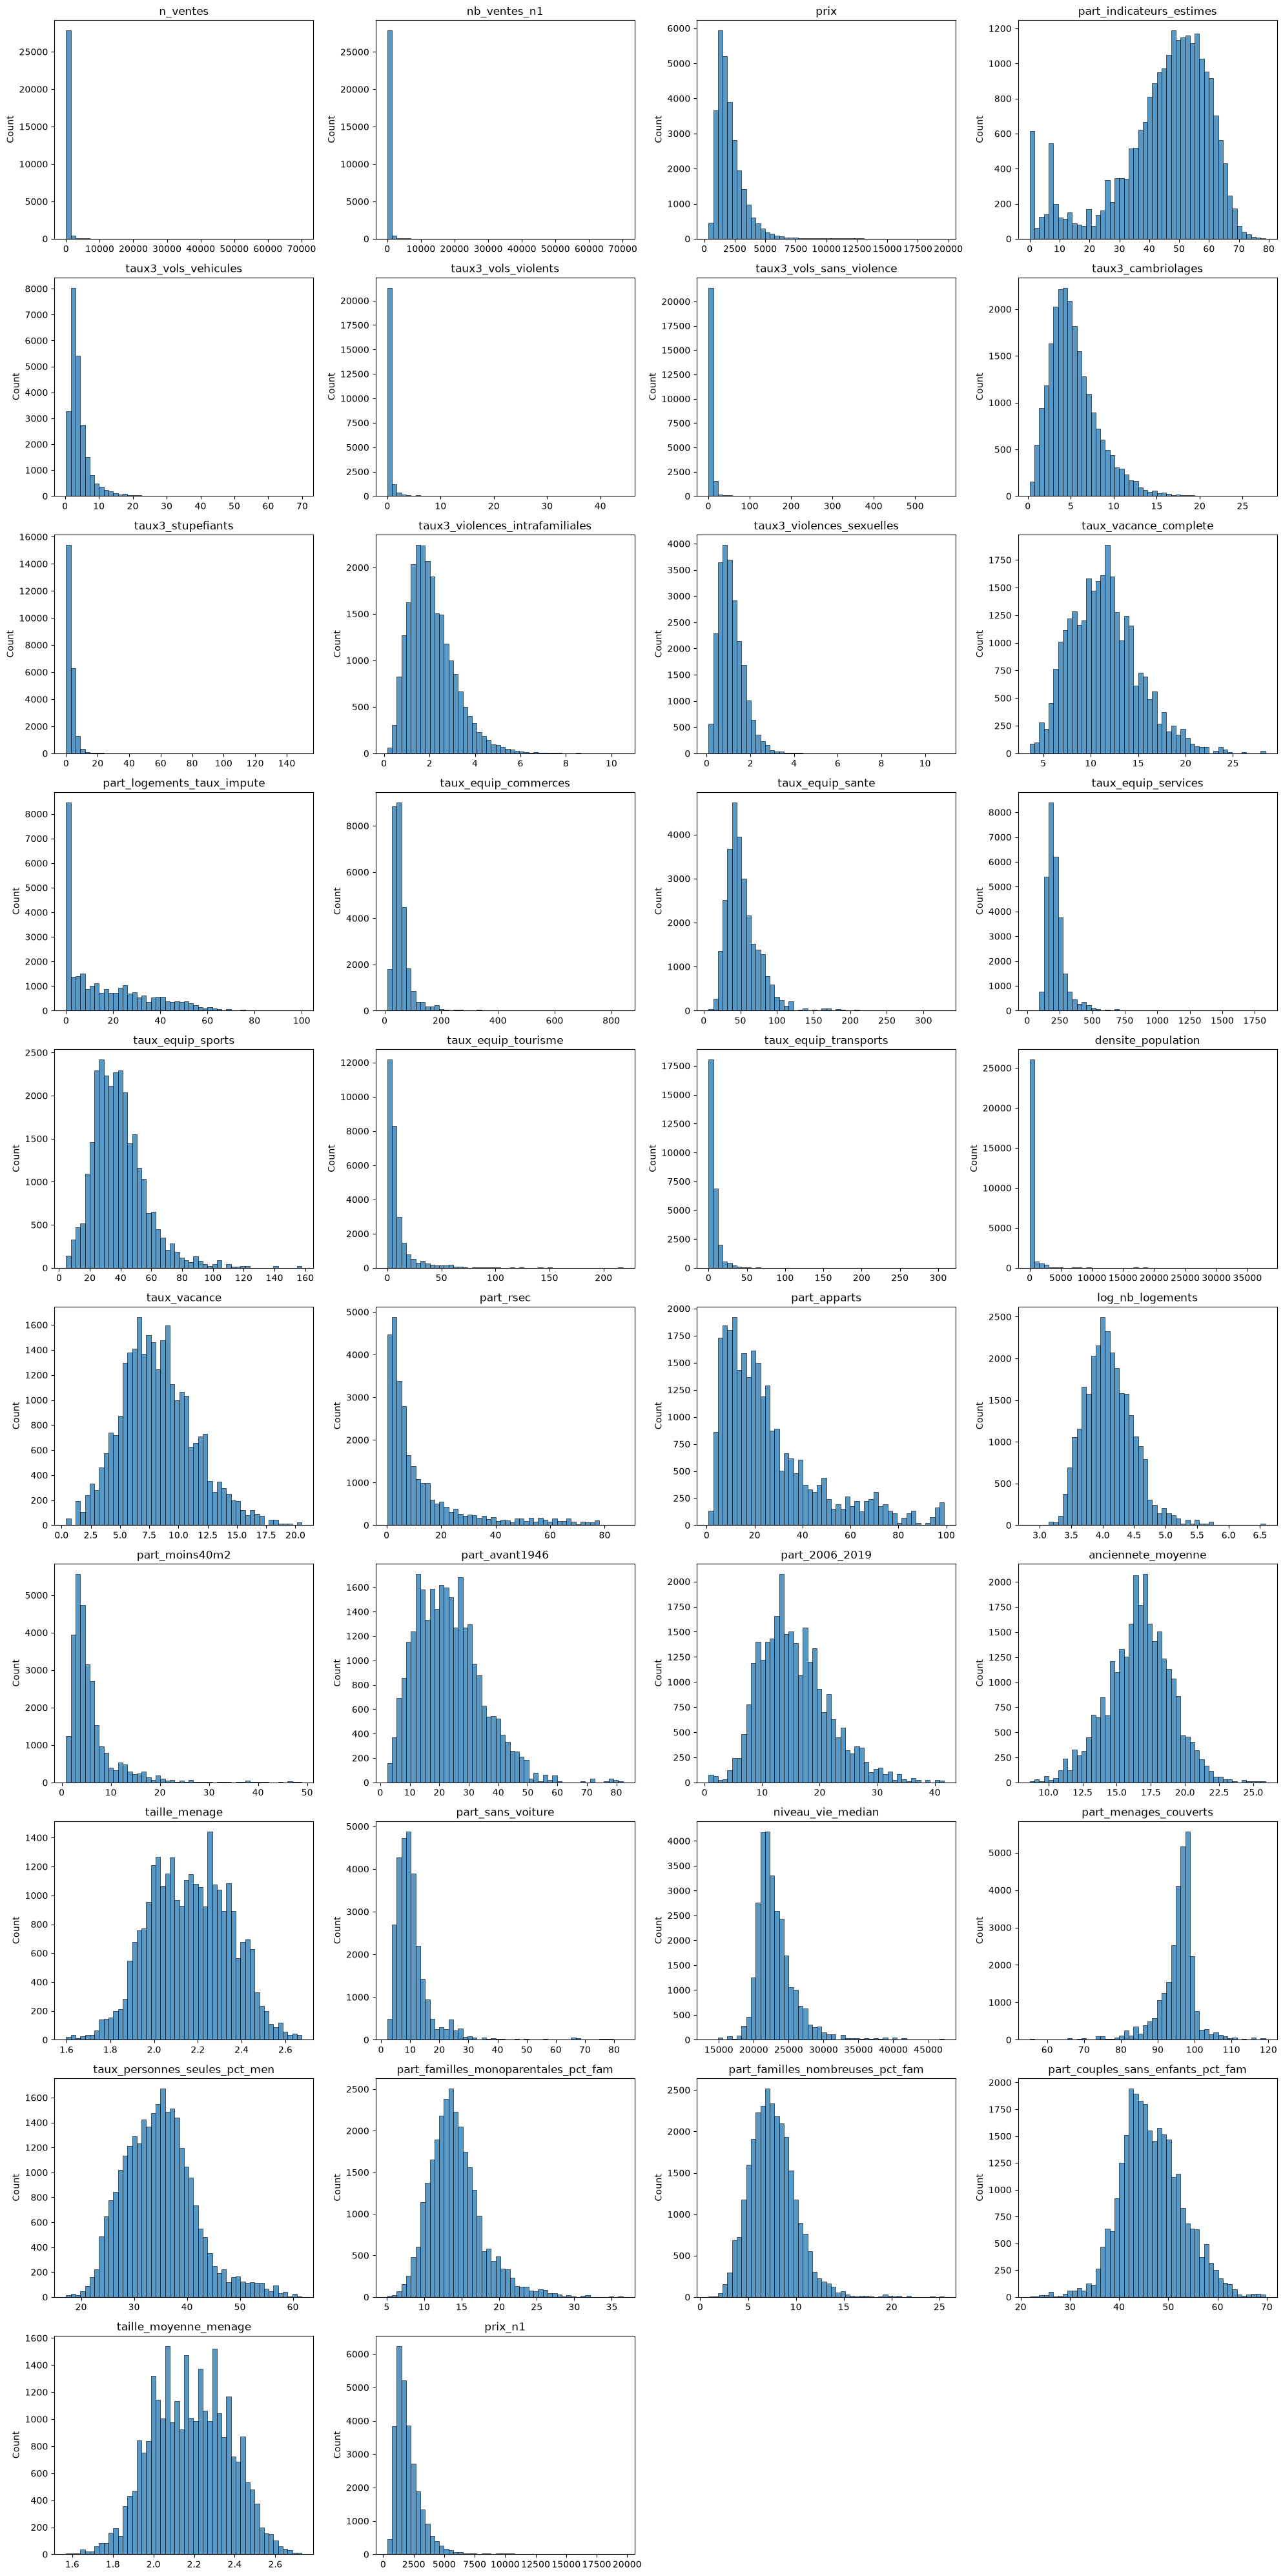

In [5]:
# Toutes les variables numériques, sauf l'année, l'indicatrice maison et l'identifiant BV2022
variables = [c for c in table.columns if c not in ["annee", "maison", "BV2022"]]

# 1. Centiles, valeurs extrêmes et asymétrie
quantiles = table[variables].describe(percentiles=[0.01, 0.05, 0.50, 0.95, 0.99]).T
quantiles["max / p99"] = quantiles["max"] / quantiles["99%"]
quantiles["asymetrie"] = table[variables].skew()
display(quantiles[["min", "1%", "5%", "50%", "95%", "99%", "max", "max / p99", "asymetrie"]].round(2))

# 2. Histogrammes de toutes les variables (4 par ligne)
n_lignes = -(-len(variables) // 4)          # division arrondie au-dessus
fig, axes = plt.subplots(n_lignes, 4, figsize=(20, 4 * n_lignes))
axes = axes.flatten()
for ax, col in zip(axes, variables):
    sns.histplot(table[col].dropna(), bins=50, ax=ax)
    ax.set_title(col)
    ax.set_xlabel("")
for ax in axes[len(variables):]:
    ax.set_visible(False)
plt.tight_layout()
plt.show()


**Lecture**

- **Règle retenue** : une variable dont l'asymétrie dépasse 1 est passée en log avant une régression linéaire ; log(1 + x) si elle contient des zéros.
- **Distributions proches de la symétrie** (asymétrie entre −1 et 1) : taux de vacance (recensement et LOVAC), ancienneté d'emménagement, taille des ménages (logement et ménages), logements anciens et récents, `log_nb_logements`, personnes seules, familles nombreuses, couples sans enfant. Pas de transformation nécessaire.
- **Longue queue vers les grandes valeurs** (asymétrie > 1), candidates à une transformation logarithmique avant une régression linéaire :
  - le prix et le prix N-1 (3,45 et 3,51) : la plupart des sous-bassins sont entre 900 et 4 300 €/m², le maximum atteint 19 652 €/m² ;
  - les ventes de N-1 (33,77) : médiane de 148 ventes, maximum de 70 042 ;
  - la densité (9,03) : médiane de 91 habitants/km², jusqu'à 37 873 dans l'arrondissement le plus dense de Paris ;
  - plusieurs taux de délinquance (vols sans violence 19,40 ; vols violents 14,23 ; stupéfiants 13,63 ; vols de véhicules 5,04) ;
  - plusieurs taux d'équipements (transports 14,65 ; commerces 6,64 ; tourisme 5,50 ; services 5,22) ;
  - logement et revenus : résidences secondaires, appartements, petits logements, ménages sans voiture, niveau de vie ;
  - ménages : familles monoparentales (1,07), juste au-dessus du seuil.
- **Valeurs isolées** (max / p99 très au-dessus de 1) : ventes de N-1 (28,1), vols sans violence (11,6 : jusqu'à 570 faits pour 1 000 habitants), stupéfiants (12,4), vols violents (8,3), équipements de transport (8,3). Ce sont des territoires où beaucoup de faits ou d'équipements se rapportent à peu d'habitants (centres touristiques, quartiers d'affaires) : des valeurs réelles, pas des erreurs.
- **Des zéros** dans plusieurs variables asymétriques (vols violents, stupéfiants, équipements de tourisme et de transport) : une transformation en log(1 + x) plutôt qu'en log(x).
- **Contrôles qualité :**
  - `part_indicateurs_estimes` : médiane de 48 %. Dans la moitié des sous-bassins, près de la moitié des indicateurs de délinquance sont estimés ; le pic à 0 correspond aux grands territoires, sans secret statistique.
  - `part_menages_couverts` : médiane de 96 %, mais 5 % des lignes dépassent 101 % (jusqu'à 119 %) : les ménages fiscaux et ceux du recensement ne sont pas définis de la même façon.

### À prendre en compte pour la modélisation : transformation logarithmique

**Règle** : asymétrie > 1 → log. **log** = log(x) · **log1p** = log(1 + x), pour les variables qui contiennent des zéros · **—** = pas de transformation

| Groupe (nombre de variables) | Variables | Régression linéaire | Modèle hiérarchique | Arbre, forêt, boosting | Réseau de neurones |
|---|---|---|---|---|---|
| Cible (1) | `prix` | log au choix | log au choix | log au choix | log au choix |
| Prix N-1 (1) | `prix_n1` | log si cible en log | log si cible en log | — | log si cible en log |
| Ventes N-1 (1) | `nb_ventes_n1` | log | log | — | log |
| Délinquance (7) | `taux3_` : vols de véhicules, vols violents, vols sans violence, cambriolages, stupéfiants, violences intrafamiliales, violences sexuelles | log (log1p : vols violents, stupéfiants) | idem | — | idem |
| Équipements (6) | `taux_equip_` : commerces, santé, services, sports, tourisme, transports | log (log1p : tourisme, transports) | idem | — | idem |
| Densité (1) | `densite_population` | log | log | — | log |
| Revenus (1) | `niveau_vie_median` | log | log | — | log |
| Logement, asymétriques (4) | `part_sans_voiture`, `part_moins40m2`, `part_rsec`, `part_apparts` | log | log | — | log |
| Logement, symétriques (6) | `taux_vacance`, `part_avant1946`, `part_2006_2019`, `anciennete_moyenne`, `taille_menage`, `log_nb_logements` | — | — | — | — |
| Vacance LOVAC (1) | `taux_vacance_complete` | — | — | — | — |
| Ménages, asymétrique (1) | `part_familles_monoparentales_pct_fam` | log | log | — | log |
| Ménages, symétriques (4) | `taux_personnes_seules_pct_men`, `part_familles_nombreuses_pct_fam`, `part_couples_sans_enfants_pct_fam`, `taille_moyenne_menage` | — | — | — | — |
| Contrôle qualité (3) | `part_indicateurs_estimes`, `part_logements_taux_impute`, `part_menages_couverts` | — | — | — | — |
| Type de bien (1) | `maison` | — | — | — | — |
| Hors modèle (3) | `annee`, `n_ventes`, `BV2022` (identifiant du bassin de vie) | — | — | — | — |

Total : 41 colonnes. Cambriolages, violences intrafamiliales et familles monoparentales sont juste au-dessus du seuil d'asymétrie (1,19 ; 1,12 ; 1,07) : leur log est facultatif. Réseau de neurones : toutes les variables sont ensuite mises à l'échelle (paramètres calculés sur les années d'apprentissage seulement). La même table peut servir à tous les modèles : le log ne change pas les coupures d'un arbre.

**⚠️ Interprétation**

| Résultat | Variable en log, cible en euros | Variable et cible en log |
|---|---|---|
| Coefficient de régression | +1 % de la variable → coefficient / 100 €/m² | +1 % de la variable → +coefficient % du prix |
| Seuil d'un arbre | seuil en log : le retransformer (exponentielle) pour le lire | idem |
| Valeur SHAP | en €/m², s'additionnent jusqu'au prix | en log : +0,05 ≈ **+5 % du prix**, jamais +0,05 €/m² ; les contributions se multiplient sur le prix en euros |
| Prévision | en €/m² | retransformer (exponentielle) avant de calculer l'erreur ; léger biais vers le bas |

### Transformation logarithmique des variables asymétriques

Variables identifiées en section 3 (asymétrie > 1). Logarithme naturel : log(x) pour les variables toujours positives, log(1 + x) pour celles qui contiennent des zéros. Transformation faite sur une copie de la table, pour l'exploration : elle n'est pas exportée. On vérifie que l'asymétrie est corrigée.

In [6]:
# Variables toujours > 0 : log(x)
LOG = ["nb_ventes_n1", "densite_population", "niveau_vie_median",
       "taux3_vols_sans_violence", "taux3_vols_vehicules",
       "taux3_violences_sexuelles", "taux3_cambriolages", "taux3_violences_intrafamiliales",
       "taux_equip_commerces", "taux_equip_services", "taux_equip_sante", "taux_equip_sports",
       "part_sans_voiture", "part_moins40m2", "part_rsec", "part_apparts",
       "part_familles_monoparentales_pct_fam"]
# Variables avec des zéros : log(1 + x)
LOG1P = ["taux3_vols_violents", "taux3_stupefiants", "taux_equip_tourisme", "taux_equip_transports"]

# Contrôle : aucune valeur <= 0 dans les variables passées en log(x) (les cases vides sont ignorées)
assert (table[LOG].min() > 0).all(), "Valeur nulle ou négative dans LOG"

table_log = table.copy()
table_log[LOG] = np.log(table_log[LOG])
table_log[LOG1P] = np.log1p(table_log[LOG1P])

# Asymétrie avant et après
asym = pd.DataFrame({"avant": table[LOG + LOG1P].skew(),
                     "après": table_log[LOG + LOG1P].skew()}).round(2)
display(asym.sort_values("avant", ascending=False))

,avant,après
nb_ventes_n1,33.77,0.52
taux3_vols_sans_violence,19.40,1.42
taux_equip_transports,14.65,0.16
taux3_vols_violents,14.23,3.66
taux3_stupefiants,13.63,0.80
densite_population,9.03,1.16
taux_equip_commerces,6.64,0.86
taux_equip_tourisme,5.50,0.71
taux_equip_services,5.22,1.07
taux3_vols_vehicules,5.04,0.35


## 4. Redondances entre variables

**Pourquoi regarder cela :** deux variables qui portent la même information n'apportent rien de plus au modèle ; en régression linéaire, elles rendent même les coefficients instables. On n'en garde alors qu'une.

**Méthode :** corrélation de Spearman entre toutes les variables explicatives, sur toutes les lignes de la table. Spearman compare les classements : il n'est pas sensible aux valeurs extrêmes ni à une transformation en log. Seuil de redondance : |rho| ≥ 0,8, comme dans l'EDA (rapport, section 4.8 ; EDA complémentaire, B1).

Hors calcul : la cible (`prix`), les variables hors modèle (`annee`, `n_ventes`) et l'indicatrice `maison`.

On regarde aussi les couples signalés comme « à contrôler » dans le feature engineering (sections 7).

In [7]:
# Variables explicatives : tout sauf la cible, les variables hors modèle, l'identifiant et l'indicatrice maison
explicatives = [c for c in table.columns if c not in ["prix", "annee", "n_ventes", "maison", "BV2022"]]
rho = table[explicatives].corr(method="spearman")

# 1. Couples redondants : |rho| >= 0,8, du plus fort au moins fort (chaque couple une seule fois)
paires = rho.where(np.triu(np.ones(rho.shape, dtype=bool), k=1)).stack().rename("rho").reset_index()
paires.columns = ["variable 1", "variable 2", "rho"]
paires = paires.reindex(paires["rho"].abs().sort_values(ascending=False).index)
print("Couples à |rho| >= 0,8 :")
display(paires[paires["rho"].abs() >= 0.8].round(2))

# 2. Couples à contrôler
# Déjà traités dans le feature engineering (une variable retirée par couple) :
#   vols sans violence / destructions, petits logements / suroccupation, sans voiture / parking
A_CONTROLER = [
    ("taux_vacance", "taux_vacance_complete"),                         # vacance : recensement / LOVAC
    ("densite_population", "log_nb_logements"),
    ("densite_population", "part_apparts"),
    ("taille_menage", "taille_moyenne_menage"),                        # même définition : logement (2022) / ménages (par année)
    ("taux_personnes_seules_pct_men", "taille_moyenne_menage"),
    ("part_familles_nombreuses_pct_fam", "taille_moyenne_menage"),
]
print("Couples à contrôler :")
display(pd.DataFrame([(a, b, round(rho.loc[a, b], 2)) for a, b in A_CONTROLER],
                     columns=["variable 1", "variable 2", "rho"]))

Couples à |rho| >= 0,8 :


,variable 1,variable 2,rho
970,taille_menage,taille_moyenne_menage,0.99
1114,taux_personnes_seules_pct_men,taille_moyenne_menage,-0.93
966,taille_menage,taux_personnes_seules_pct_men,-0.92


Couples à contrôler :


,variable 1,variable 2,rho
0,taux_vacance,taux_vacance_complete,0.63
1,densite_population,log_nb_logements,0.46
2,densite_population,part_apparts,0.46
3,taille_menage,taille_moyenne_menage,0.99
4,taux_personnes_seules_pct_men,taille_moyenne_menage,-0.93
5,part_familles_nombreuses_pct_fam,taille_moyenne_menage,0.52


**Comment lire les tableaux (exemple : taille des ménages du parc de logements et taille moyenne des ménages, rho = 0,99) :**
- **Ce que mesure rho :** on classe les sous-bassins selon la taille des ménages calculée avec le parc de logements, puis selon celle calculée avec les données des ménages, et on compare les deux classements.
- **Le signe :** positif, les deux variables montent ensemble ; négatif, l'une monte quand l'autre baisse (part de personnes seules et taille moyenne des ménages, rho = −0,93 : plus il y a de personnes seules, plus la taille moyenne baisse).
- **La valeur :** 0,99 veut dire que les deux classements sont presque identiques. Repères : 0,1 lien faible, 0,3 moyen, 0,5 fort ; au-delà de 0,8, les deux variables portent presque la même information.

**Constat :**
- **Les trois redondances repérées au premier audit ont été traitées dans le feature engineering** : `part_suroccupes`, `part_parking` et `taux3_destructions` ont été retirées.
- **Un trio redondant (|rho| ≥ 0,9), entre deux sources** : taille des ménages du parc de logements (`taille_menage`), taille moyenne des ménages (`taille_moyenne_menage`, 0,99) et part de personnes seules (`taux_personnes_seules_pct_men`, −0,92 et −0,93). Les deux tailles ont la même définition ; la part de personnes seules en est le reflet direct. Il faut n'en garder qu'une sur les trois.
- **Couples à contrôler, sous le seuil :** vacance du recensement / vacance LOVAC (0,63) : liées, mais elles ne mesurent pas la même chose (tout le parc ou le parc privé). Densité / nombre de logements et densité / part d'appartements (0,46) : pas de redondance. Familles nombreuses / taille moyenne des ménages (0,52) : liées, sans redondance.
- Hors de ce trio, chaque source apporte sa propre information.

## 5. Importance des variables

Pour voir rapidement quelles variables comptent le plus pour prévoir le prix : deux modèles simples (régression linéaire, forêt aléatoire), un par type de bien, lus avec SHAP. Ce n'est pas une évaluation de modèle : sans le prix N-1, réglages non optimisés.

### 5.1 Données d'apprentissage

Table transformée en log (section 3), prix de 2017 à 2023 (ni la validation 2024, ni le test 2025). Les lignes avec une case vide sont retirées, la régression linéaire ne les accepte pas.

In [8]:
import shap
from sklearn.linear_model import LinearRegression

AVEC_PRIX_N1 = False   # True : prix N-1 inclus (il domine tout)

variables = [c for c in explicatives if AVEC_PRIX_N1 or c != "prix_n1"] + ["maison"]
apprentissage = table_log[(table_log["annee"] >= 2017) & (table_log["annee"] <= 2023)]

# Diagnostic : cases vides restantes de 2017 à 2023, par variable et par année
vides = apprentissage[variables].isna()
print("Variables avec des cases vides :")
print(vides.sum()[vides.sum() > 0].to_string())
print("Lignes concernées par année :")
print(vides.any(axis=1).groupby(apprentissage["annee"]).sum().to_string())

# La régression n'accepte pas les cases vides : lignes retirées
apprentissage = apprentissage.dropna(subset=variables)
print("Lignes gardées :", len(apprentissage))

Variables avec des cases vides :
taux_vacance_complete         7
part_logements_taux_impute    7
Lignes concernées par année :
annee
2017    1
2018    1
2019    1
2020    1
2021    1
2022    1
2023    1
Lignes gardées : 18286


**Lecture :** seules `taux_vacance_complete` et `part_logements_taux_impute` (LOVAC) ont des cases vides : une ligne par année, un sous-bassin sans donnée LOVAC. 18 286 lignes gardées.

### 5.2 SHAP par type de bien (régression linéaire, toutes les variables)

Une régression linéaire par type de bien (maisons, appartements), mêmes réglages que ci-dessus : table transformée en log, prix de 2017 à 2023, lignes sans donnée LOVAC retirées, cible en €/m². On compare quelles variables comptent pour chaque marché.

Background dataset has 12453 samples but max_samples=100. Subsampling to 100 samples for SHAP value computation. To use all samples, set max_samples=12453 when initializing the masker.


Maisons : 12453 lignes d'apprentissage


Background dataset has 5833 samples but max_samples=100. Subsampling to 100 samples for SHAP value computation. To use all samples, set max_samples=5833 when initializing the masker.


Appartements : 5833 lignes d'apprentissage


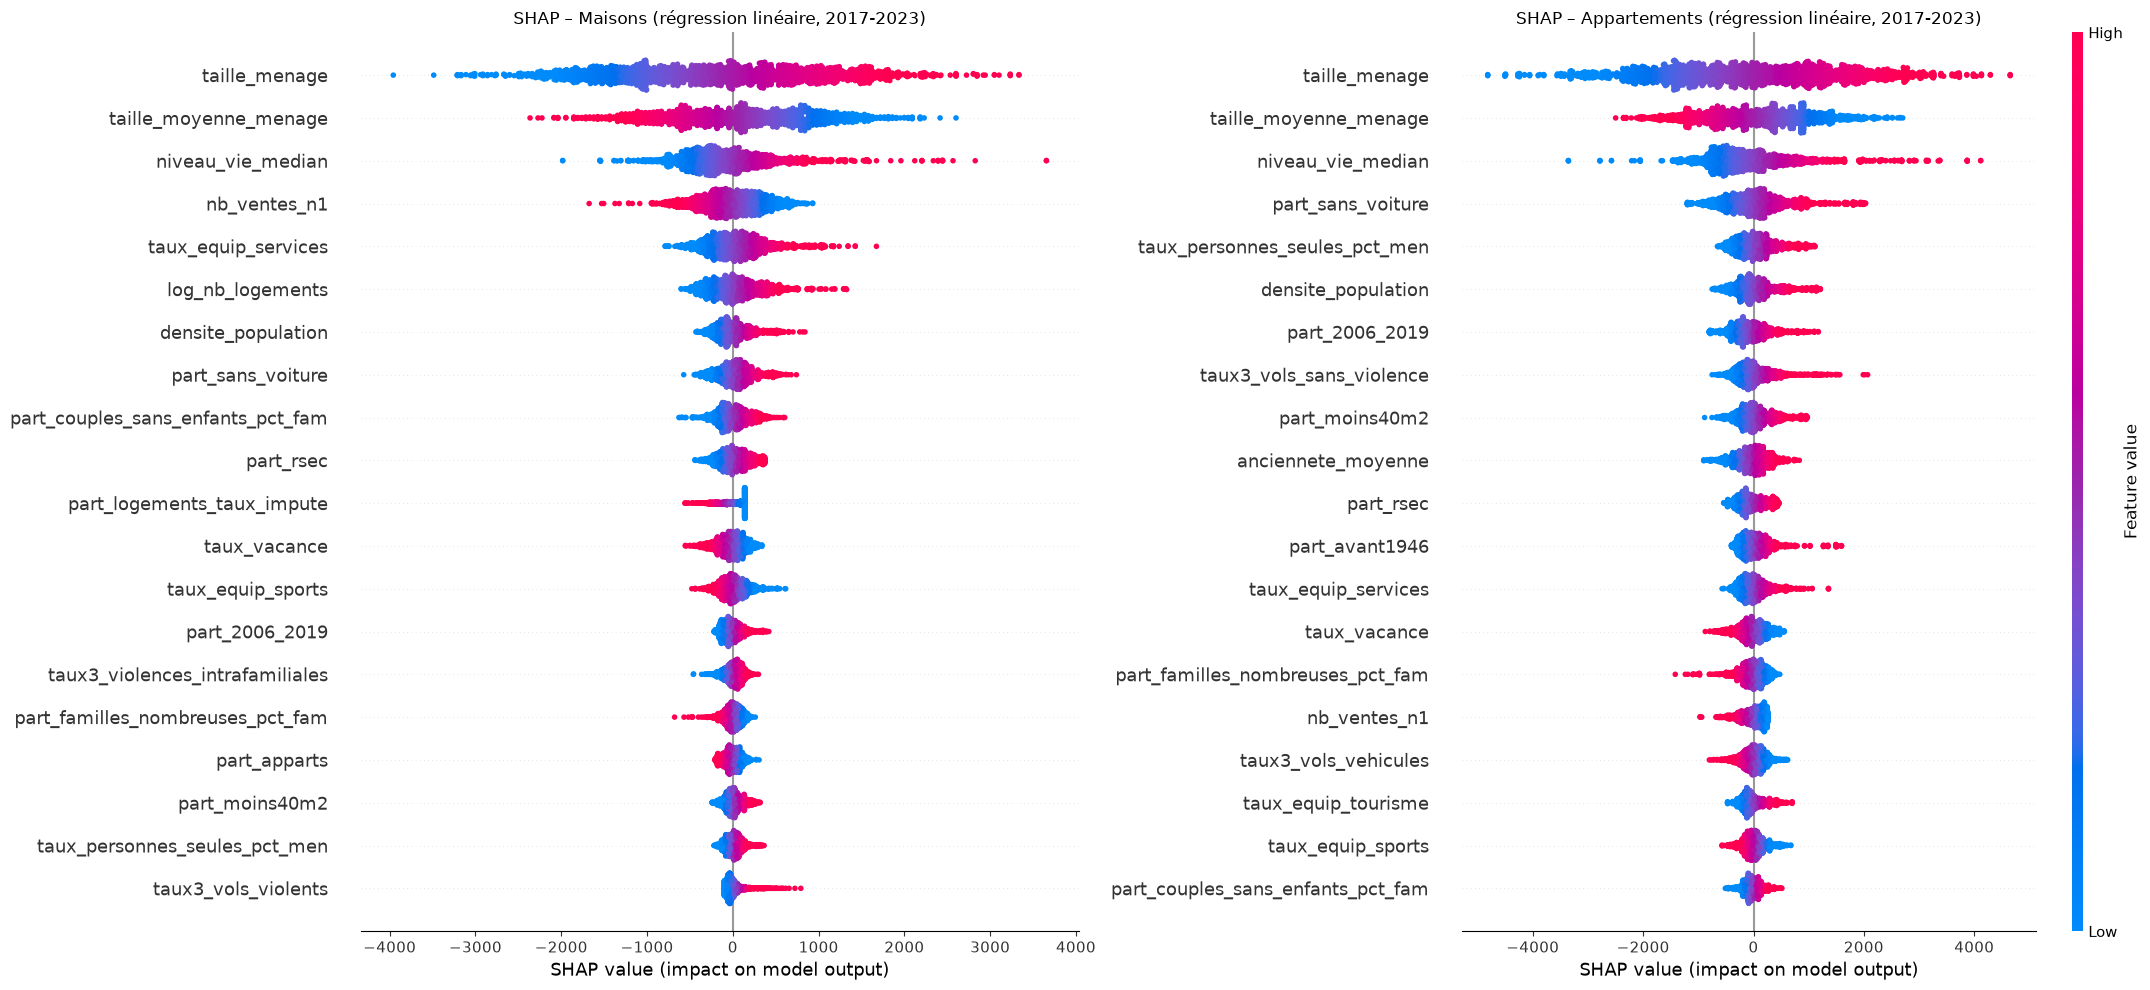

In [9]:
variables_type = [c for c in explicatives if AVEC_PRIX_N1 or c != "prix_n1"]   # sans "maison"

plt.figure(figsize=(22, 10))
for i, (nom, valeur) in enumerate([("Maisons", 1), ("Appartements", 0)], start=1):
    app_type = apprentissage[apprentissage["maison"] == valeur]
    X_t, y_t = app_type[variables_type], app_type["prix"]
    modele_t = LinearRegression().fit(X_t, y_t)

    echantillon_t = X_t.sample(min(2000, len(X_t)), random_state=42)
    valeurs_t = shap.LinearExplainer(modele_t, X_t).shap_values(echantillon_t)
    print(nom, ":", len(X_t), "lignes d'apprentissage")

    # Chaque graphique se dessine dans sa moitié de la figure
    plt.subplot(1, 2, i)
    shap.summary_plot(valeurs_t, echantillon_t, max_display=20, show=False,
                      plot_size=None, color_bar=(i == 2))
    plt.title(f"SHAP – {nom} (régression linéaire, 2017-2023)")

plt.tight_layout()
plt.show()

**Comment lire les graphiques :** chaque point est un sous-bassin × année. Sa position dit de combien la variable fait monter (à droite) ou baisser (à gauche) le prix prévu, en €/m², par rapport au prix moyen. Sa couleur donne la valeur de la variable : rouge = élevée, bleu = faible. Les variables sont classées de la plus utilisée à la moins utilisée.
*Exemple : pour les appartements, un niveau de vie élevé (points rouges) ajoute jusqu'à environ +4 000 €/m² au prix prévu ; un niveau de vie faible (points bleus) retire jusqu'à environ −3 400 €/m².*

**Ce qui domine les deux modèles : un effet de la redondance**
- **Les deux tailles des ménages arrivent en tête, avec des effets opposés** : une taille élevée selon le parc de logements (`taille_menage`) fait monter le prix, une taille élevée selon les données des ménages (`taille_moyenne_menage`) le fait baisser. Ces deux variables ont la même définition (rho = 0,99) : le modèle se sert de leur petite différence et leur donne de très grandes contributions, de sens contraires. Ce n'est pas un effet réel sur le prix. La part de personnes seules, troisième variable du même trio (rho = −0,93), est aussi concernée.

**Ce qui est commun aux deux marchés**
- **Le niveau de vie est la variable réelle la plus forte**, juste après le trio : de −2 000 à +3 600 €/m² environ pour les maisons, de −3 400 à +4 200 €/m² pour les appartements.
- **Même sens pour plusieurs variables** : une forte vacance fait baisser le prix ; beaucoup de logements récents (2006-2019), de résidences secondaires et de couples sans enfant le font monter ; beaucoup de familles nombreuses et d'équipements de sport (signe d'un territoire rural) le font baisser.

**Ce qui distingue les deux marchés**
- **Maisons : le cadre de vie du territoire.** Après le niveau de vie viennent les ventes de l'année précédente (beaucoup de ventes, prix plus bas), les équipements de services, la taille du parc et la densité. Le prix des maisons suit ce qu'offre le territoire autour.
- **Appartements : la centralité urbaine.** Après le niveau de vie viennent les ménages sans voiture, les personnes seules, la densité, les logements récents, les vols sans violence, les petits logements et les logements d'avant 1946. Ce sont des marqueurs de centres-villes, où les appartements sont les plus chers. Les ventes de l'année précédente n'arrivent qu'en 16e position.

**Limites : ce que ces graphiques ne permettent pas de conclure**
- **Ce n'est pas une relation de cause à effet** : les vols ne font pas monter les prix ; ils signalent des centres-villes, où les prix sont élevés.
- **Les variables liées entre elles se partagent ou s'opposent leurs contributions.** Leurs signes ne sont pas à interpréter séparément : le trio des ménages ci-dessus, violences intrafamiliales / violences sexuelles (rho = 0,7), ventes de N-1 / nombre de logements (rho = 0,6). La part d'appartements fait baisser le prix des maisons, alors qu'elle est liée positivement à la densité et aux petits logements.
- **Une variable de contrôle qualité est utilisée par le modèle des maisons** : `part_logements_taux_impute` (taux de vacance complété par l'intercommunalité) y sert d'indice du caractère rural.
- **Régression linéaire simple**, sans le prix N-1, sur les prix 2017-2023 : 12 453 lignes pour les maisons, 5 833 pour les appartements. Ce n'est pas une évaluation de modèle.

**Conséquences pour la modélisation**
- Les marchés n'utilisent pas les mêmes variables : cela conforte le choix de modéliser maisons et appartements séparément.
- Le trio taille du parc / taille moyenne des ménages / personnes seules est à réduire à une seule variable, dans le feature engineering.
- Les variables de contrôle qualité restent hors des modèles (décision d'équipe) : elles servent seulement à l'analyse des erreurs.

### 5.3 Effet du retrait des variables redondantes

Une variable retirée par couple redondant : `part_suroccupes` (gardée : `part_moins40m2`), `part_parking` (gardée : `part_sans_voiture`), `taux3_destructions` (gardée : `taux3_vols_sans_violence`). Critère : lien le plus fort et le plus stable avec le prix, pour les deux types de bien.

**Évaluation :** régression linéaire par type de bien, entraînée sur les prix de 2017 à 2023, mesurée sur 2024 (année de validation ; 2025 reste réservée au test). Deux mesures :
- **R²** : part des écarts de prix entre sous-bassins que le modèle explique (1 = tout, 0 = rien) ;
- **MAE** : erreur moyenne en €/m², en valeur absolue.

Sans le prix N-1, l'erreur reste élevée : l'objectif est de comparer les deux jeux de variables, pas d'évaluer un modèle final.

In [15]:
from sklearn.metrics import r2_score, mean_absolute_error

# Déjà retirées dans le feature engineering (absentes de la table) : part_suroccupes, part_parking, taux3_destructions
# Trio redondant des ménages (|rho| >= 0,92) : on garde la part de personnes seules, on retire les deux tailles
RETIREES = ["taille_menage", "taille_moyenne_menage"]
JEUX = {"toutes les variables": variables_type,
        "sans redondances": [c for c in variables_type if c not in RETIREES]}

# Validation : prix 2024, lignes sans donnée LOVAC retirées
validation = table_log[table_log["annee"] == 2024].dropna(subset=variables_type)

resultats, modeles = [], {}
for nom_jeu, vars_jeu in JEUX.items():
    for nom, valeur in [("Maisons", 1), ("Appartements", 0)]:
        app_t = apprentissage[apprentissage["maison"] == valeur]
        val_t = validation[validation["maison"] == valeur]
        modele_t = LinearRegression().fit(app_t[vars_jeu], app_t["prix"])
        modeles[(nom_jeu, nom)] = (modele_t, app_t[vars_jeu])
        resultats.append({
            "variables": nom_jeu, "type": nom, "nb variables": len(vars_jeu),
            "R² apprentissage": r2_score(app_t["prix"], modele_t.predict(app_t[vars_jeu])),
            "R² validation 2024": r2_score(val_t["prix"], modele_t.predict(val_t[vars_jeu])),
            "MAE validation 2024 (€/m²)": mean_absolute_error(val_t["prix"], modele_t.predict(val_t[vars_jeu])),
        })
display(pd.DataFrame(resultats).round(2))

,variables,type,nb variables,R² apprentissage,R² validation 2024,MAE validation 2024 (€/m²)
0,toutes les variables,Maisons,35,0.80,0.74,437.75
1,toutes les variables,Appartements,35,0.87,0.85,519.70
2,sans redondances,Maisons,33,0.79,0.79,330.91
3,sans redondances,Appartements,33,0.86,0.86,476.18


Background dataset has 12453 samples but max_samples=100. Subsampling to 100 samples for SHAP value computation. To use all samples, set max_samples=12453 when initializing the masker.
Background dataset has 5833 samples but max_samples=100. Subsampling to 100 samples for SHAP value computation. To use all samples, set max_samples=5833 when initializing the masker.


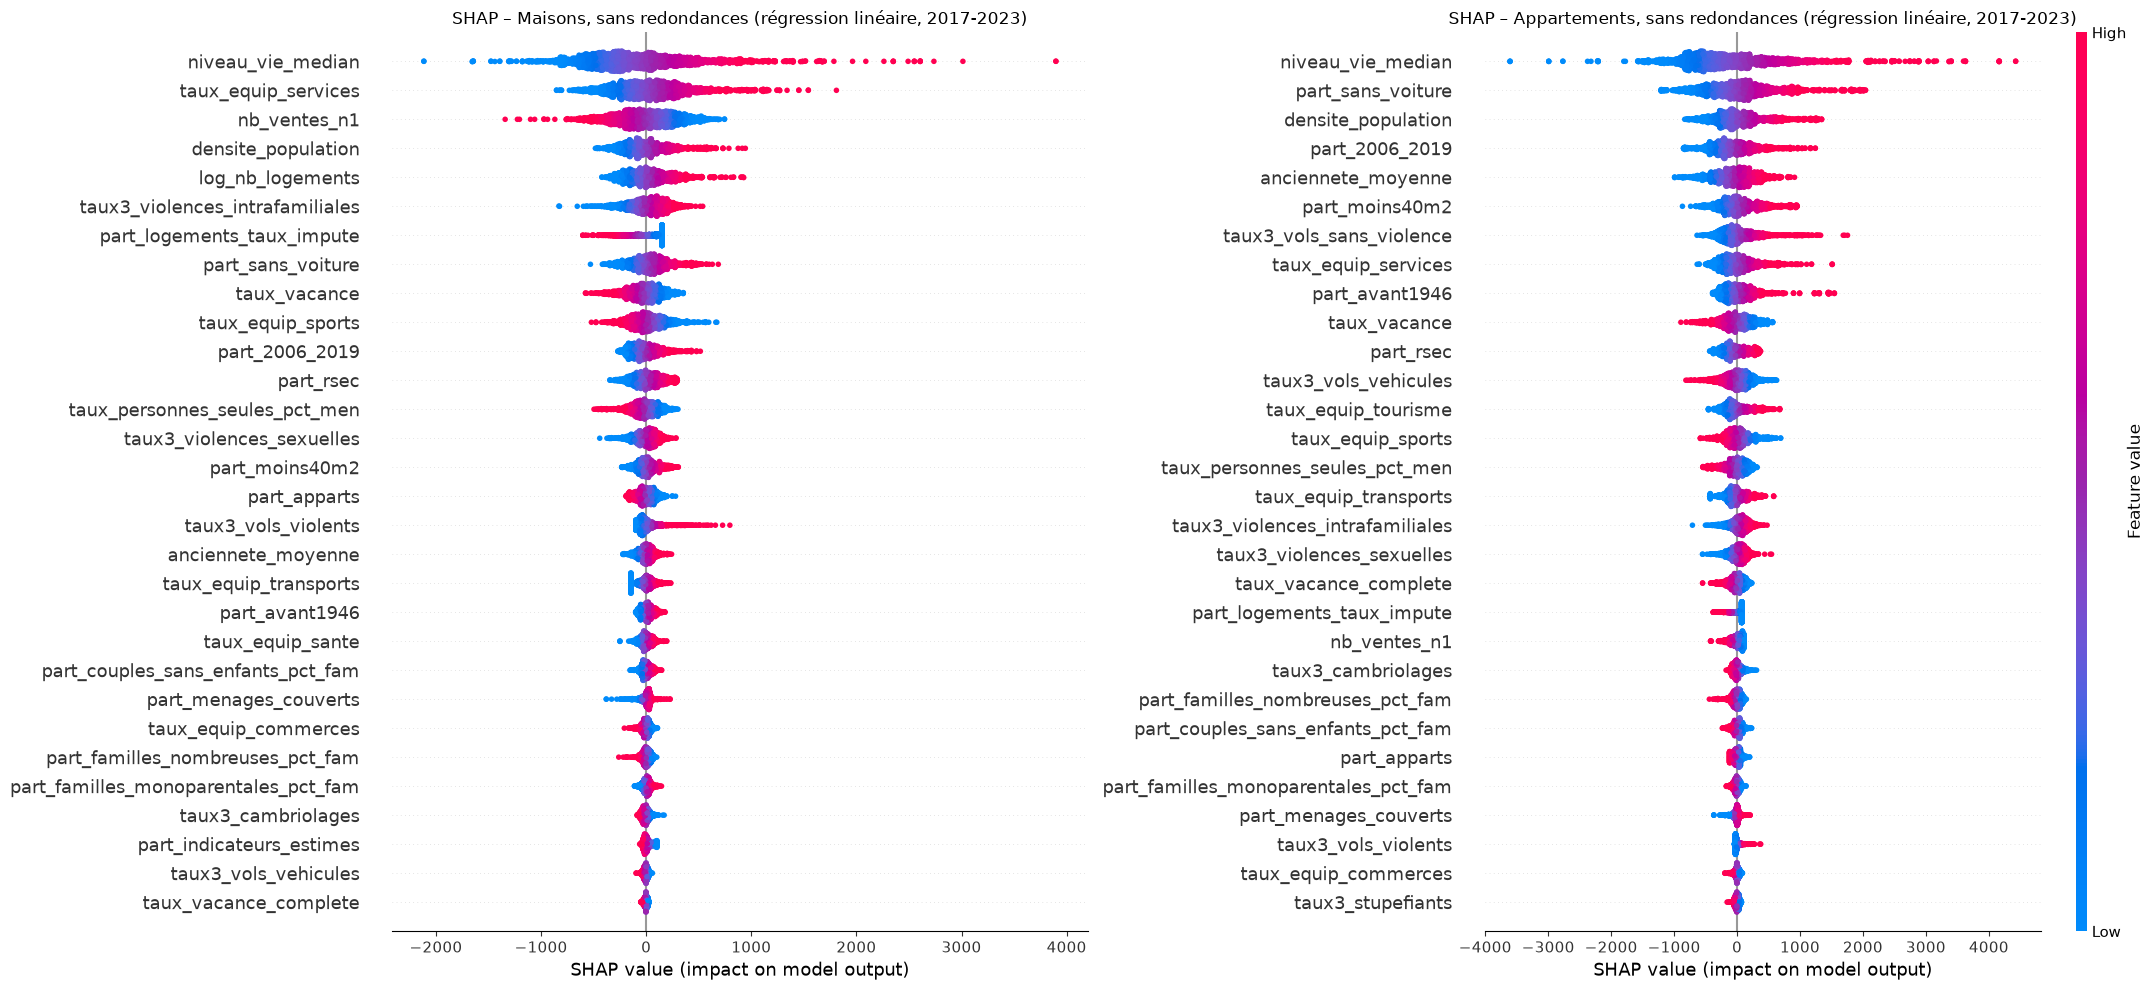

In [16]:
plt.figure(figsize=(22, 10))
for i, nom in enumerate(["Maisons", "Appartements"], start=1):
    modele_t, X_t = modeles[("sans redondances", nom)]
    echantillon_t = X_t.sample(min(2000, len(X_t)), random_state=42)
    valeurs_t = shap.LinearExplainer(modele_t, X_t).shap_values(echantillon_t)

    plt.subplot(1, 2, i)
    shap.summary_plot(valeurs_t, echantillon_t, max_display=30, show=False,
                      plot_size=None, color_bar=(i == 2))
    plt.title(f"SHAP – {nom}, sans redondances (régression linéaire, 2017-2023)")

plt.tight_layout()
plt.show()

**Comment lire le tableau (exemple : maisons, sans redondances) :**
- **R² validation 2024 = 0,79** : le modèle explique 79 % des écarts de prix entre sous-bassins en 2024, une année qu'il n'a pas vue.
- **R² apprentissage = 0,79** : même valeur sur les années d'entraînement. Un R² nettement plus haut en apprentissage qu'en validation signalerait un modèle qui apprend par cœur ou qui ne se généralise pas.
- **MAE = 331 €/m²** : en 2024, le prix prévu d'un sous-bassin s'écarte en moyenne de 331 €/m² du prix réel.

**Constat :**
- **Le trio redondant des ménages dégradait le modèle.** Avec les deux tailles des ménages, le R² de validation des maisons tombe à 0,74 alors qu'il est de 0,80 en apprentissage, et l'erreur atteint 438 €/m². Sans elles, les deux R² sont égaux (0,79) et l'erreur baisse de 107 €/m² (−24 %). Pour les appartements, l'erreur baisse de 44 €/m² (−8 %), de 520 à 476 €/m².
- **Explication probable** : les deux tailles portent la même information, et le modèle s'appuie sur leur petite différence, avec de très grands coefficients de signes opposés. En 2024, l'une est une photo fixe (2022), l'autre une valeur prolongée : leur différence change un peu, et ces grands coefficients amplifient ce changement dans la prévision.
- **Sans redondances, pas de surapprentissage** : R² d'apprentissage et de validation égaux (0,79 maisons, 0,86 appartements).
- **Les variables du territoire seules expliquent 79 à 86 % des écarts de prix entre sous-bassins**, sans le prix de l'année précédente. L'erreur reste élevée (331 et 476 €/m²) : ces variables disent où les prix sont hauts ou bas, pas comment ils évoluent d'une année à l'autre.

**SHAP sans redondances :**
- **Le niveau de vie passe en tête pour les deux types de bien**, de −2 100 à +3 900 €/m² environ pour les maisons, de −3 600 à +4 400 €/m² pour les appartements. Plus aucune variable ne domine en s'opposant à une autre.
- **Maisons** : viennent ensuite les équipements de services, les ventes de N-1 (beaucoup de ventes, prix plus bas), la densité et la taille du parc. Une forte vacance et beaucoup d'équipements de sport font baisser le prix.
- **Appartements** : viennent ensuite les ménages sans voiture, la densité, les logements récents (2006-2019), l'ancienneté d'emménagement, les petits logements et les vols sans violence : des marqueurs de centres-villes.
- **La part de personnes seules a changé de sens** : tant que les deux tailles étaient présentes, une part élevée faisait monter le prix ; seule, elle le fait baisser, pour les deux types de bien. Les signes du trio n'étaient pas interprétables.
- **Un signe à lire avec prudence** : seule, la part de ménages sans voiture est liée négativement au prix ; dans le modèle, elle le fait monter. C'est l'effet *à niveau de vie et densité égaux* : parmi des territoires de même revenu et de même densité, ceux où beaucoup de ménages vivent sans voiture (centres-villes) sont plus chers.
- **Une variable de contrôle qualité pèse dans le modèle des maisons** : `part_logements_taux_impute` (7e variable). Elle y sert d'indice du caractère rural ; elle restera hors des modèles (décision d'équipe).
- **Des variables peu utilisées dans les deux modèles** : vacance LOVAC, équipements de commerces, cambriolages, familles monoparentales et nombreuses. La vacance LOVAC apporte peu à côté de celle du recensement. Ce sont des candidates à tester en retrait à la modélisation, pas à retirer sur cette seule base (un arbre peut les utiliser autrement).
- **Ventes de N-1 et nombre de logements** (rho = 0,6) continuent de s'opposer pour les maisons : à surveiller.

**Conséquence :** retirer `taille_menage` et `taille_moyenne_menage` dans le feature engineering ; garder `taux_personnes_seules_pct_men`.

### 5.4 Comparaison avec une forêt aléatoire

Forêt aléatoire (200 arbres, profondeur 10, au moins 20 lignes par feuille) par type de bien, mêmes variables (table en log, sans redondances), entraînée sur les prix de 2017 à 2023, mesurée sur 2024. Le log ne change rien pour la forêt (mêmes coupures) : il est gardé pour comparer avec la régression sur la même table.

In [17]:
from sklearn.ensemble import RandomForestRegressor

vars_rf = JEUX["sans redondances"]
resultats_rf, modeles_rf = [], {}
for nom, valeur in [("Maisons", 1), ("Appartements", 0)]:
    app_t = apprentissage[apprentissage["maison"] == valeur]
    val_t = validation[validation["maison"] == valeur]
    foret = RandomForestRegressor(n_estimators=200, max_depth=10, min_samples_leaf=20,
                                  n_jobs=-1, random_state=42).fit(app_t[vars_rf], app_t["prix"])
    modeles_rf[nom] = (foret, app_t[vars_rf])
    resultats_rf.append({
        "modèle": "forêt aléatoire", "type": nom,
        "R² apprentissage": r2_score(app_t["prix"], foret.predict(app_t[vars_rf])),
        "R² validation 2024": r2_score(val_t["prix"], foret.predict(val_t[vars_rf])),
        "MAE validation 2024 (€/m²)": mean_absolute_error(val_t["prix"], foret.predict(val_t[vars_rf])),
    })

# Comparaison avec la régression linéaire sans redondances
lineaire = (pd.DataFrame(resultats).query("variables == 'sans redondances'")
            .drop(columns=["variables", "nb variables"]).assign(**{"modèle": "régression linéaire"}))
display(pd.concat([lineaire, pd.DataFrame(resultats_rf)])
        .sort_values(["type", "modèle"]).round(2).reset_index(drop=True))

,type,R² apprentissage,R² validation 2024,MAE validation 2024 (€/m²),modèle
0,Appartements,0.94,0.91,353.18,forêt aléatoire
1,Appartements,0.86,0.86,476.18,régression linéaire
2,Maisons,0.87,0.88,219.68,forêt aléatoire
3,Maisons,0.79,0.79,330.91,régression linéaire


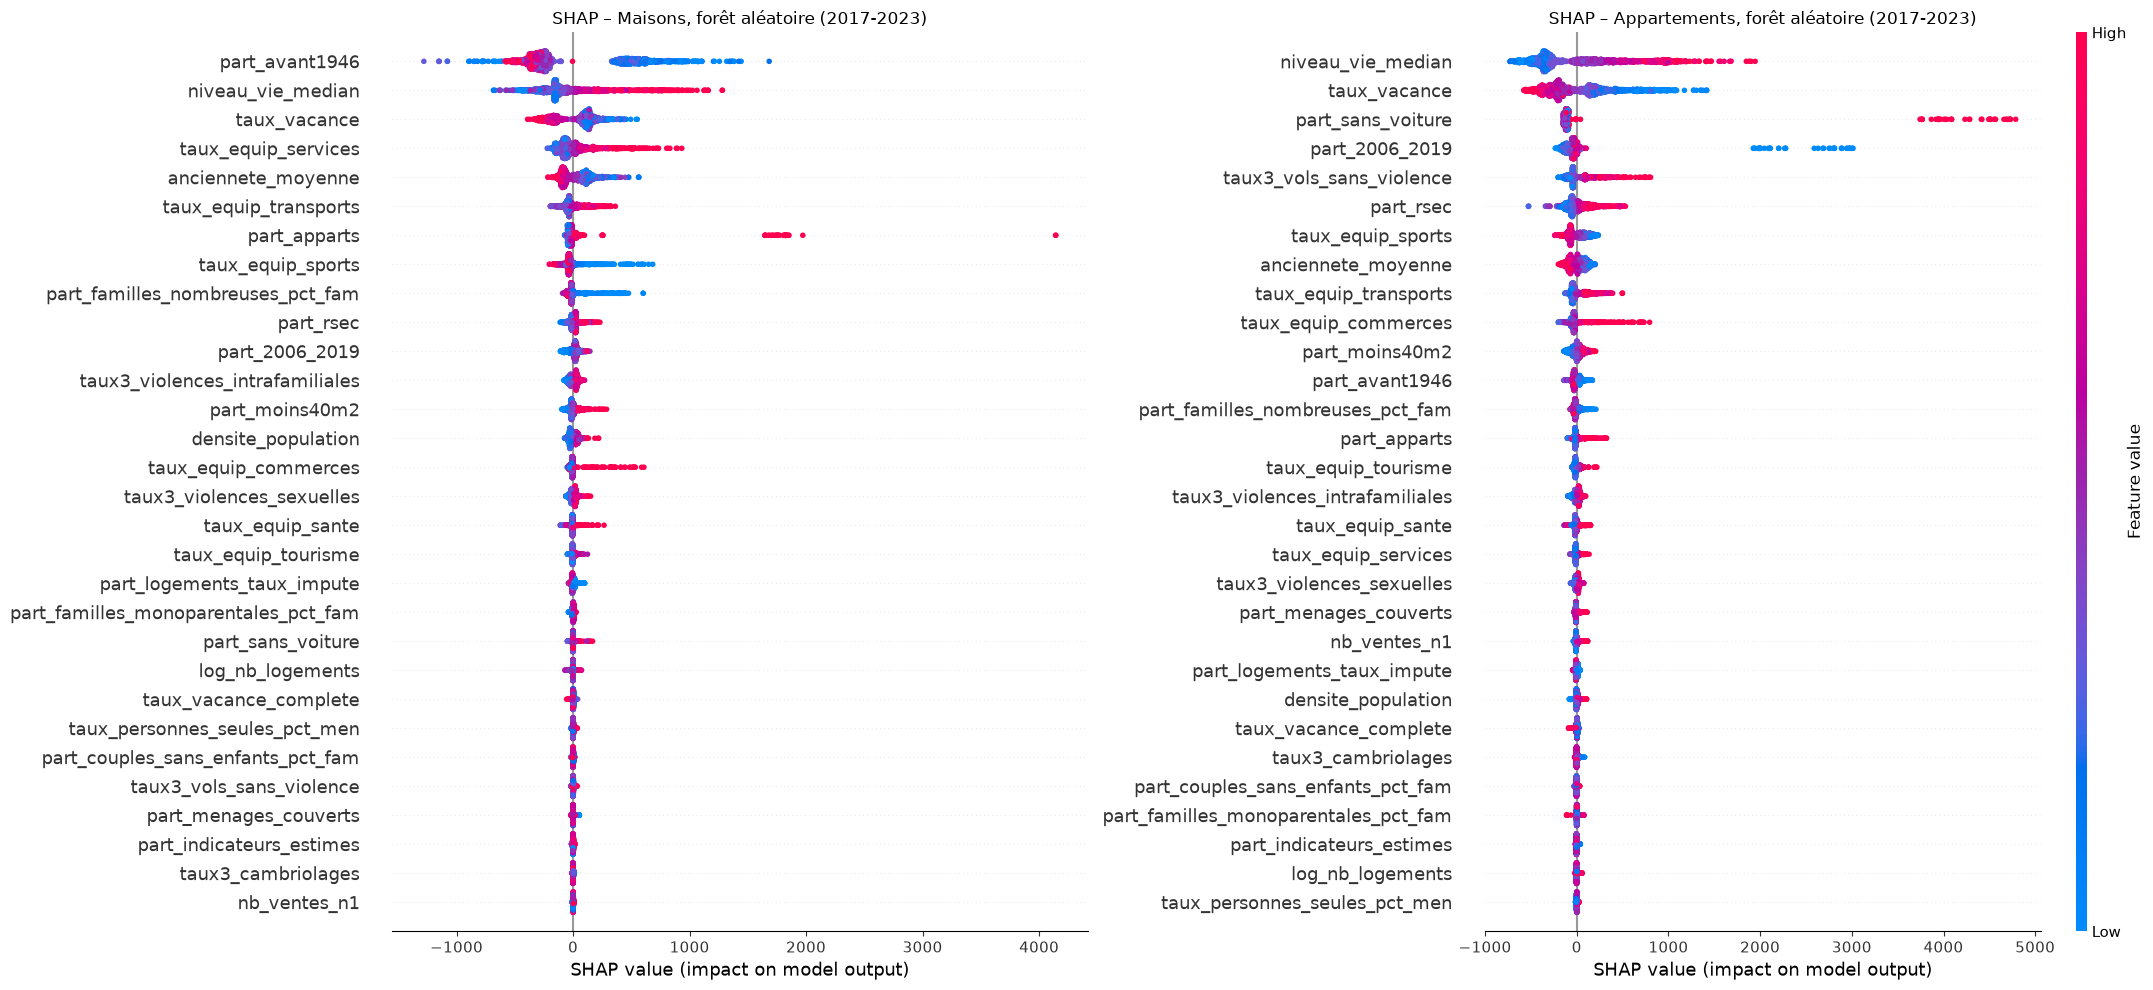

In [18]:
plt.figure(figsize=(22, 10))
for i, nom in enumerate(["Maisons", "Appartements"], start=1):
    foret, X_t = modeles_rf[nom]
    echantillon_t = X_t.sample(min(2000, len(X_t)), random_state=42)
    valeurs_t = shap.TreeExplainer(foret).shap_values(echantillon_t)

    plt.subplot(1, 2, i)
    shap.summary_plot(valeurs_t, echantillon_t, max_display=30, show=False,
                      plot_size=None, color_bar=(i == 2))
    plt.title(f"SHAP – {nom}, forêt aléatoire (2017-2023)")

plt.tight_layout()
plt.show()

**Comment lire le tableau (exemple : maisons) :** la forêt aléatoire explique 88 % des écarts de prix en 2024 (R² validation), contre 79 % pour la régression linéaire, et son erreur moyenne baisse de 331 à 220 €/m² (−34 %). Pour les appartements, l'erreur passe de 476 à 353 €/m² (−26 %). R² d'apprentissage et de validation restent proches (0,87 / 0,88 pour les maisons ; 0,94 / 0,91 pour les appartements) : pas de surapprentissage marqué.

**Constat :**
- **La forêt prévoit nettement mieux que la régression** : une partie des liens avec le prix n'est pas en ligne droite (effets de seuil) ou dépend des autres variables (interactions). C'est ce que montre le mélange des couleurs dans son SHAP.
- **Les variables les plus utilisées changent d'un modèle à l'autre.** La régression donne l'effet de chaque variable, les autres égales ; la forêt choisit une variable par groupe de variables liées (logements anciens pour les maisons, vacance pour les appartements). L'importance dépend du modèle, pas seulement de la variable.
- **Effets de seuil visibles pour les maisons :** peu de logements d'avant 1946 ajoutent de 300 à 1 700 €/m², beaucoup en retirent environ 300 ; quelques territoires très urbains (forte part d'appartements) ajoutent de 1 600 à 2 000 €/m², un seul jusqu'à 4 100 €/m².
- **Des paquets isolés pour les appartements** : une très forte part de ménages sans voiture ajoute de 3 700 à 4 800 €/m², une très faible part de logements récents de 1 900 à 3 000 €/m². Ces paquets regroupent probablement les arrondissements de Paris : la forêt reconnaît Paris à ces deux variables. Ce n'est pas un effet général de ces variables.
- **La densité n'est presque plus utilisée par la forêt** (22e variable pour les appartements) : maintenant que chaque arrondissement a sa propre densité, elle ne sert plus d'étiquette « Paris ».
- **Ce qui ressort des deux modèles** (conclusions solides) : niveau de vie, vacance, ancienneté d'emménagement, équipements de services et de sport, résidences secondaires, logements récents parmi les variables les plus utilisées ; délinquance peu utile en dehors des vols sans violence (appartements) ; variables de contrôle qualité, vacance LOVAC et part de personnes seules peu utilisées.
- Ce n'est pas une évaluation de modèle final : sans prix N-1, réglages non optimisés, années 2017-2023.

### 5.5 Variables qui ne comptent dans aucun modèle

Pour chacun des 4 modèles (régression et forêt, maisons et appartements) : part de chaque variable dans l'importance totale, à partir des valeurs SHAP (moyenne en valeur absolue). On garde la part la plus élevée des quatre : une variable sous 2 % dans tous les modèles ne compte nulle part. Seuil indicatif : avec 30 variables, une variable moyenne pèse environ 3 %.

In [19]:
# Part de chaque variable dans l'importance SHAP totale de chaque modèle (en %)
parts = {}
for nom in ["Maisons", "Appartements"]:
    modele_lin, X_t = modeles[("sans redondances", nom)]
    foret, _ = modeles_rf[nom]
    echantillon_t = X_t.sample(min(2000, len(X_t)), random_state=42)
    for nom_modele, valeurs in [
        ("régression", shap.LinearExplainer(modele_lin, X_t).shap_values(echantillon_t)),
        ("forêt", shap.TreeExplainer(foret).shap_values(echantillon_t)),
    ]:
        imp = pd.Series(np.abs(valeurs).mean(axis=0), index=X_t.columns)
        parts[f"{nom} – {nom_modele}"] = imp / imp.sum() * 100

parts = pd.DataFrame(parts)
parts["part max (%)"] = parts.max(axis=1)
parts["compte nulle part (< 2 %)"] = parts["part max (%)"] < 2
display(parts.sort_values("part max (%)").round(1))

Background dataset has 12453 samples but max_samples=100. Subsampling to 100 samples for SHAP value computation. To use all samples, set max_samples=12453 when initializing the masker.
Background dataset has 5833 samples but max_samples=100. Subsampling to 100 samples for SHAP value computation. To use all samples, set max_samples=5833 when initializing the masker.


,Maisons – régression,Maisons – forêt,Appartements – régression,Appartements – forêt,part max (%),compte nulle part (< 2 %)
taux3_stupefiants,0.2,0.1,0.5,0.1,0.5,True
part_indicateurs_estimes,0.8,0.1,0.2,0.2,0.8,True
part_familles_monoparentales_pct_fam,1.0,0.4,0.8,0.2,1.0,True
part_menages_couverts,1.1,0.1,0.7,0.7,1.1,True
taux3_cambriolages,0.9,0.1,1.1,0.3,1.1,True
part_couples_sans_enfants_pct_fam,1.2,0.2,1.1,0.2,1.2,True
taux_equip_sante,1.4,0.8,0.5,1.0,1.4,True
taux_vacance_complete,0.4,0.2,1.9,0.4,1.9,True
taux3_vols_violents,2.2,0.1,0.7,0.1,2.2,False
part_familles_nombreuses_pct_fam,1.0,2.7,1.1,1.4,2.7,False


**Comment lire le tableau (exemple : `taux3_cambriolages`) :** dans chacun des 4 modèles, les cambriolages pèsent au plus 1,1 % de l'importance totale (régression des appartements). Avec 33 variables, une variable moyenne pèse environ 3 % : les cambriolages ne comptent dans aucun modèle.

**Constat :**
- **8 variables comptent pour moins de 2 % dans les 4 modèles** :
  - deux variables de contrôle qualité : `part_indicateurs_estimes` (0,8 % au plus), `part_menages_couverts` (1,1 %) ;
  - deux indicateurs de délinquance : stupéfiants (0,5 %), cambriolages (1,1 %) ;
  - deux variables des ménages : familles monoparentales (1,0 %), couples sans enfant (1,2 %) ;
  - les équipements de santé (1,4 %) ;
  - la vacance LOVAC (1,9 %), qui n'apporte rien à côté de la vacance du recensement (jusqu'à 16,5 %).
- **Juste au-dessus du seuil** : vols violents (2,2 %), familles nombreuses et violences sexuelles (2,7 %).
- **Des variables fortes dans un seul type de modèle**, à ne pas retirer :
  - logements d'avant 1946 : 28 % dans la forêt des maisons, 1,5 % dans la régression ;
  - ventes de N-1 (7,9 %) et taille du parc (5,4 %) : régression des maisons seulement ;
  - ménages sans voiture : 9 à 11 % pour les appartements, presque rien dans la forêt des maisons ;
  - densité : régressions seulement (5,6 et 6,2 %).
- **Les variables qui comptent partout** : niveau de vie (15 à 23 %), vacance du recensement (4 à 17 %), logements récents, ancienneté d'emménagement, résidences secondaires et équipements de sport.
- **La délinquance apporte peu** : 2 des 7 indicateurs ne comptent nulle part. Seuls les vols sans violence (appartements, 4,6 et 5,6 %) et les violences intrafamiliales (régression des maisons, 4,7 %) dépassent 4 % dans un modèle.
- **Les ménages apportent peu** une fois le trio réduit : la part de personnes seules ne pèse que dans les régressions (3,2 et 2,8 %), les familles monoparentales et les couples sans enfant ne comptent nulle part.
- **Une variable de contrôle qualité pèse dans la régression des maisons** : `part_logements_taux_impute` (4,7 %), indice du caractère rural ; elle restera hors des modèles.

# Synthèse : audit et EDA de la table de modélisation

L'audit est relancé à chaque évolution de la table de modélisation. Chaque version ajoute ses constats ; les versions précédentes sont gardées, avec la suite donnée à chaque action.

## Version 1 : table à 38 colonnes (avant le retrait des 3 variables redondantes)

| Constat majeur | Preuve | Conséquence projet | Action | Suite donnée |
|---|---|---|---|---|
| La table compte une seule variable par information | Sections 1 et 2 : 28 450 lignes, 38 colonnes ; délinquance en taux lissés sur 3 ans, équipements pour 10 000 habitants, densité, part des ménages couverts ; un seul nombre restant (`nb_ventes_n1`) | Les territoires de tailles différentes sont comparables | Fait dans le feature engineering | — |
| Peu de valeurs vides, toutes expliquées | Délinquance vide pour les prix 2015-2016 (17,4 %) ; LOVAC vide pour un sous-bassin (11 lignes) | La régression linéaire refuse les cases vides | À la modélisation : retirer ces lignes (ou les compléter) pour les modèles qui l'exigent | Fait : le masque de `commun.py` retire une seule fois les lignes à case vide, pour tous les modèles |
| 22 variables très asymétriques, avec des valeurs isolées réelles | Section 3 : asymétrie > 1 ; valeurs isolées = centres touristiques, Paris | Une régression linéaire serait tirée par quelques territoires | Log pour la régression, le modèle hiérarchique et le réseau de neurones ; inutile pour les arbres | Décision d'équipe : log dans les notebooks de modélisation, pour les seuls modèles qui en ont besoin |
| Trois couples de variables redondantes | Section 4 : petits logements / suroccupation (0,88), sans voiture / parking (−0,84), vols sans violence / destructions (0,78) ; SHAP de la régression : une variable gardée au hasard, ou les deux opposées | Retirer `part_suroccupes`, `part_parking`, `taux3_destructions` ne change ni le R² ni l'erreur (+1 %) | Retirer ces 3 variables avant la modélisation | Fait : retirées dans le feature engineering (03/11/2026) |
| Les variables du territoire expliquent l'essentiel du niveau des prix | Régression linéaire sans prix N-1, validée sur 2024 : R² 0,80 (maisons) et 0,86 (appartements), sans surapprentissage ; erreur de 329 et 476 €/m² | Elles disent où les prix sont hauts ou bas, pas comment ils évoluent | Le prix N-1 et les variables de marché restent indispensables pour l'évolution | — |
| La forêt aléatoire prévoit mieux que la régression linéaire | Validation 2024, sans prix N-1 : erreur de 221 contre 329 €/m² (maisons), 350 contre 476 €/m² (appartements) ; R² 0,88 et 0,91 contre 0,80 et 0,86 | Effets de seuil et interactions : une partie des liens avec le prix n'est pas en ligne droite | Comparer régression et modèles à arbres à la modélisation | Repris dans la feuille de route (progression du plus simple au plus complexe) |
| Les variables importantes dépendent du modèle et du type de bien ; un noyau commun | SHAP régression et forêt : niveau de vie, vacance, ancienneté d'emménagement, équipements de services et de sport, résidences secondaires en haut des deux. La densité sert d'étiquette « Paris » pour la forêt | Modéliser maisons et appartements séparément ; ne pas conclure sur un seul modèle | Densité par arrondissement à envisager | Fait : superficie réelle de chaque arrondissement (bloc 1 de la préparation) |
| 7 variables ne comptent dans aucun modèle | Part de l'importance SHAP < 2 % dans les 4 modèles : `part_indicateurs_estimes`, `part_menages_couverts`, `taux3_stupefiants`, `taux3_cambriolages`, `taux3_vols_violents`, `taux_equip_sante`, `taux_vacance_complete`. `part_logements_taux_impute` sert d'indice rural dans la régression des maisons (4,5 %) | Elles alourdissent les modèles sans les améliorer | Candidates au retrait, à confirmer à la modélisation ; variables de contrôle qualité : retrait à décider | Décision d'équipe : variables de contrôle qualité hors modèle, pour l'analyse des erreurs seulement |

## Version 2 : table à 41 colonnes (04/11/2026)

Changements de la table : 3 variables redondantes retirées ; 5 variables des ménages ajoutées (recensements 2019-2022, une valeur par année) ; `BV2022` ajouté (identifiant du bassin de vie, pour le test contre la naïve) ; densité calculée avec la superficie réelle de chaque arrondissement.

| Constat majeur | Preuve | Conséquence projet | Action | Suite donnée |
|---|---|---|---|---|
| La table reste propre | 28 450 lignes, 41 colonnes, index unique ; valeurs vides seulement pour la délinquance des prix 2015-2016 (17,4 %) ; ménages sans aucune case vide | Rien ne change pour le masque commun | — | — |
| Un trio redondant entre deux sources | Section 4 : `taille_menage` (logement) / `taille_moyenne_menage` (ménages) rho = 0,99 ; avec `taux_personnes_seules_pct_men` −0,93 et −0,92. SHAP de la régression : les deux tailles en tête, avec des effets opposés | Le trio dégrade la prévision : avec les deux tailles, R² de validation des maisons 0,74 (0,80 en apprentissage) et erreur de 438 €/m² ; sans elles, 0,79 et 331 €/m² (−24 %). Appartements : 520 → 476 €/m² (−8 %) | Retirer `taille_menage` et `taille_moyenne_menage` ; garder `taux_personnes_seules_pct_men`, la plus fine (2 616 valeurs) et la plus parlante pour les besoins des ménages | À faire dans le feature engineering |
| Une variable des ménages à passer en log | Section 3 : familles monoparentales, asymétrie 1,07 (juste au-dessus du seuil de 1), sans zéro ; les 4 autres variables des ménages sont symétriques | Même règle que pour les autres variables | Ajouter `part_familles_monoparentales_pct_fam` à `LOG` ; retirer `part_suroccupes` et `taux3_destructions` des listes. Listes à jour : 17 variables en log, 4 en log(1 + x) | Fait dans l'audit et dans le notebook H3b ; à reporter dans `modelisation_template.ipynb` |
| La densité ne sert plus d'étiquette « Paris » | SHAP de la forêt : densité 22e pour les appartements. Paris est désormais reconnu par d'autres variables : très forte part de ménages sans voiture (+3 700 à +4 800 €/m²), très faible part de logements récents (+1 900 à +3 000 €/m²) | Les paquets isolés regroupent probablement les arrondissements parisiens (à vérifier) | — | — |
| Sans le trio, mêmes résultats d'ensemble qu'en version 1 | Régression : R² 0,79 (maisons) et 0,86 (appartements), erreur de 331 et 476 €/m², sans surapprentissage. Forêt : R² 0,88 et 0,91, erreur de 220 et 353 €/m² | Les conclusions de la version 1 tiennent | — | — |
| 8 variables ne comptent dans aucun modèle | Part de l'importance SHAP < 2 % dans les 4 modèles : `part_indicateurs_estimes`, `part_menages_couverts`, `taux3_stupefiants`, `taux3_cambriolages`, `taux_equip_sante`, `taux_vacance_complete`, `part_familles_monoparentales_pct_fam`, `part_couples_sans_enfants_pct_fam`. Juste au-dessus : vols violents (2,2 %) | Les ménages apportent peu une fois le trio réduit : la part de personnes seules ne pèse que dans les régressions (3,2 et 2,8 %) | Candidates au retrait, à confirmer à la modélisation (erreur avec et sans) | — |
| Une variable de contrôle qualité pèse dans un modèle | `part_logements_taux_impute` : 4,7 % dans la régression des maisons, indice du caractère rural | Confirme qu'elle mesure en partie le territoire, pas seulement la donnée | Hors modèle (décision d'équipe) | Appliqué par le template de modélisation |